# Modelagem do risco de detrator

Este notebook treina e avalia o modelo que estima, logo após a entrega, a probabilidade de o cliente responder à pesquisa de NPS como detrator. A pergunta, o uso do score e o plano de avaliação estão na [estratégia preditiva](../reports/estrategia_preditiva.md), e o plano foi fixado antes do treino (D-18): dois candidatos comparados por validação cruzada no treino, testes de robustez e uma única avaliação no teste, contra a regra de dias de atraso e o modelo ingênuo (D-14 e D-15).

Três regras valem para todo o notebook. O teste só é lido na seção 10, depois da revisão da seção 9, e nenhuma escolha anterior usa os pedidos dele (D-11). A ROC-AUC é a métrica principal, e a PR-AUC, a de apoio (D-12). E, como a base é simulada (D-10), os números valem como demonstração de método.

O modelo final é gerado pelo comando `python -m src.modeling.train`, com a mesma função da seção 2, e fica em `models/`, fora do Git.

In [1]:
# Importações
from loguru import logger
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import brier_score_loss, roc_auc_score

# Logs do projeto desligados para não gravar caminhos da máquina local nas saídas
logger.disable("src")

from src.analysis import ranking_metrics
from src.features import load_processed_data
from src.modeling.evaluation import (
    SCORE_RANKING,
    auc_difference,
    calibration_table,
    cv_splits,
    error_by_group,
    out_of_fold,
    permutation_importance_cv,
    reference_criteria,
)
from src.modeling.models import (
    BOOSTING,
    CHECKOUT_FEATURES,
    DELIVERY,
    EXCLUDED,
    FEATURE_LABELS,
    FEATURES,
    LINEAR,
    ORDER,
    PROFILE,
    SEARCH_SPACES,
    SERVICE,
    TARGET,
    build_regressor,
    tune,
    with_features,
)
from src.modeling.predict import LONG_DELAY_DAYS
from src.modeling.train import train_model
from src.plots import ACCENT, INK, plot_calibration, plot_roc_curves, save_figure, set_style
from src.split import TEST, TRAIN, split_train_test

set_style()

# Só o treino até a seção 10; o teste fica separado e intocado (D-11)
processed = load_processed_data()
split = split_train_test(processed)
train = processed[split == TRAIN]
x_train, y_train = train[FEATURES], train[TARGET]
delay_rule = train["delivery_delay_days"]
print(f"{len(train)} pedidos de treino, {y_train.mean():.1%} de detratores")


2000 pedidos de treino, 84.4% de detratores


## 1. Variáveis do modelo

As variáveis são as da D-06, agrupadas pelo momento em que o dado existe: cadastro, pedido, entrega e atendimento. Ficam fora a nota, que define o alvo, o CSAT, a recompra e os identificadores. O modelo recebe as colunas como a base as registra. Os atributos de `src/features.py` repetem essa informação em faixas e indicadores, úteis para ler a análise exploratória, mas dispensáveis aqui: o gradient boosting encontra os próprios cortes, e a análise exploratória não encontrou, nas variáveis associadas aos detratores, ponto de ruptura que pedisse um corte fixo na regressão logística (seção 6 da [análise exploratória](02_eda.ipynb)). A região é a única variável de categoria.

In [2]:
moments = {"cadastro": PROFILE, "pedido": ORDER, "entrega": DELIVERY, "atendimento": SERVICE}

# Nenhuma variável proibida pela D-06 pode entrar no modelo
assert not set(FEATURES) & set(EXCLUDED)
print(f"Fora do modelo: {', '.join(EXCLUDED)}")

pd.DataFrame(
    {
        "variáveis": [", ".join(columns) for columns in moments.values()],
        "no cenário de checkout": [
            set(columns) <= set(CHECKOUT_FEATURES) for columns in moments.values()
        ],
    },
    index=list(moments),
)


Fora do modelo: nps_score, csat_internal_score, repeat_purchase_30d, customer_id, order_id


,variáveis,no cenário de checkout
cadastro,"customer_age, customer_region, customer_tenure...",True
pedido,"order_value, items_quantity, discount_value, p...",True
entrega,"delivery_time_days, delivery_delay_days, deliv...",False
atendimento,"customer_service_contacts, resolution_time_day...",False


## 2. Candidatos na validação cruzada

Regressão logística e gradient boosting, cada um com 20 combinações de hiperparâmetros sorteadas e medidas nas mesmas cinco partes do treino, estratificadas pela variável-alvo (D-18). A melhor combinação de cada candidato prevê depois o risco de todos os pedidos de treino fora da amostra: cada pedido recebe o risco de um modelo ajustado sem ele. São essas previsões que comparam os candidatos entre si e com as referências, o modelo ingênuo e a regra de dias de atraso, que não têm nada a ajustar e são medidas no treino inteiro. Vence o candidato de maior ROC-AUC ou, se a diferença for de até 0,01, a regressão logística, o mais simples dos dois. Como a busca escolhe os hiperparâmetros nas mesmas partes que medem o resultado, a estimativa sai levemente otimista; a palavra final é do teste.

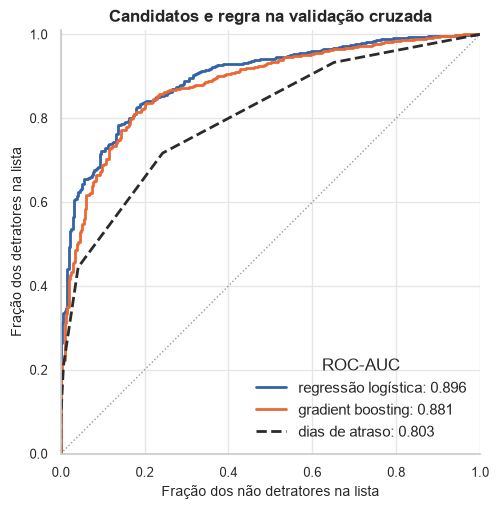

,hiperparâmetros,escolhido
regressão logística,{'C': 0.1445},True
gradient boosting,"{'l2_regularization': 0.004937, 'learning_rate...",False


,PR-AUC,ROC-AUC,precisão no topo,captura no topo
regressão logística,0.978,0.896,1.000,0.237
gradient boosting,0.974,0.881,0.992,0.235
dias de atraso,0.944,0.803,0.995,0.236
modelo ingênuo,0.844,0.500,0.840,0.199


In [3]:
model, candidates, cv_risk = train_model(train)
chosen = candidates.index[candidates["escolhido"]][0]
scores = {**cv_risk, "dias de atraso": delay_rule}

fig, ax = plt.subplots(figsize=(5.5, 5.5))
plot_roc_curves(
    y_train,
    scores,
    reference="dias de atraso",
    ax=ax,
    title="Candidatos e regra na validação cruzada",
)
save_figure(fig, "modelo_02_candidatos")
plt.show()

display(candidates[["hiperparâmetros", "escolhido"]])
references = {**scores, "modelo ingênuo": np.zeros(len(train))}
pd.DataFrame(
    {name: ranking_metrics(y_train, score) for name, score in references.items()}
).T.round(3)


**A regressão logística vence por desempenho, e não pelo desempate: supera o gradient boosting por uma diferença maior que a margem de 0,01 e fica acima da regra de dias de atraso em toda a curva.** Num par sorteado de detrator e não detrator, o modelo dá o risco maior ao detrator cerca de nove em cada dez vezes, contra oito da regra, que não tem como ordenar pedidos com os mesmos dias de atraso: são os trechos retos da curva dela. No topo de 20% da lista, os dois candidatos e a regra reúnem quase só detratores, e por isso precisão e captura não separam as ordenações, como a D-12 previa.

## 3. Regressão da nota como comparação

A alternativa à classificação é prever a nota, de 0 a 10, e ordenar os clientes da menor para a maior nota prevista (D-17). Entram as duas famílias, regressão linear com regularização e gradient boosting, com a mesma busca, as mesmas partes e as mesmas variáveis dos candidatos. A busca da regressão escolhe os hiperparâmetros pela própria ROC-AUC da ordenação, para a comparação não favorecer a classificação. Se a melhor regressão ordenar melhor que o candidato escolhido, a escolha é revista antes do teste.

In [4]:
splits = cv_splits(x_train, y_train)
orderings = {f"classificação: {chosen}": cv_risk[chosen]}
for kind in [LINEAR, BOOSTING]:
    search = tune(
        build_regressor(kind),
        SEARCH_SPACES[kind],
        x_train,
        train["nps_score"],
        splits,
        scoring=SCORE_RANKING,
    )
    # Nota prevista menor, risco maior
    predicted_score = out_of_fold(search.best_estimator_, x_train, train["nps_score"], splits)
    orderings[f"regressão: {kind}"] = -predicted_score

comparison = pd.DataFrame(
    {name: ranking_metrics(y_train, score) for name, score in orderings.items()}
).T
best_regression = comparison.iloc[1:]["ROC-AUC"].idxmax()
display(comparison.round(3))

difference = auc_difference(y_train, cv_risk[chosen], orderings[best_regression])
pd.DataFrame({f"classificação menos {best_regression}": difference}).T.round(3)


,PR-AUC,ROC-AUC,precisão no topo,captura no topo
classificação: regressão logística,0.978,0.896,1.0,0.237
regressão: regressão linear,0.979,0.898,1.0,0.237
regressão: gradient boosting,0.978,0.894,1.0,0.237


,diferença,IC inferior,IC superior
classificação menos regressão: regressão linear,-0.002,-0.006,0.002


**Prever a nota não ordena os clientes melhor que prever o detrator: a melhor regressão empata com a regressão logística, e a diferença entre as duas fica dentro do acaso.** O intervalo da diferença cruza o zero, e nas três ordenações o topo de 20% da lista só tem detratores. Com a ordenação empatada, a escolha da D-17 se apoia nos argumentos de negócio: a probabilidade de detrator responde à meta e à decisão de pôr ou não o cliente na lista, e a nota prevista, não.